# **Marketing Campaign Graduation Project**



## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

##Loading Data

In [2]:
mkt_df = pd.read_csv("/content/marketing_campaign.csv")

## Inspecting Data

In [3]:
mkt_df.head()

,Campaign_ID,Date,Channel,Campaign_Type,Audience,Budget_EGP,Spend_EGP,Impressions,Clicks,Conversions,Revenue_EGP,Landing_Page_Version,Region
0,CMP-5001,5/31/2026,TikTok Ads,Conversion,Interest-Based,8533.22,7336.40,355232,6525,332.0,219693.23,B,Mansoura
1,CMP-5002,9/14/2026,Instagram Ads,Conversion,Lookalike,4473.55,3436.57,152266,3342,130.0,100991.78,B,Cairo
2,CMP-5003,4/13/2026,Facebook Ads,Conversion,Remarketing,4707.64,4037.88,189581,4856,146.0,102674.67,C,Assiut
3,CMP-5004,8/9/2026,Google Ads,Traffic,Remarketing,3487.93,NaN,193571,8771,132.0,80683.17,C,Mansoura
4,CMP-5005,4/27/2026,Google Ads,Retargeting,Broad Audience,1013.50,984.85,37221,1197,99.0,61234.12,C,Assiut


In [4]:
mkt_df.tail()

,Campaign_ID,Date,Channel,Campaign_Type,Audience,Budget_EGP,Spend_EGP,Impressions,Clicks,Conversions,Revenue_EGP,Landing_Page_Version,Region
1409,CMP-5578,5/19/2026,Facebook Ads,Conversion,Interest-Based,13352.36,10057.74,617256,19626,1018.0,449122.24,B,Cairo
1410,CMP-5881,3/23/2026,TikTok Ads,Conversion,Existing Customers,10781.05,10214.58,384125,5597,356.0,188047.59,B,Mansoura
1411,CMP-5492,6/4/2026,Facebook Ads,Lead Generation,Remarketing,10026.86,9156.75,465470,19621,1126.0,621555.52,A,Cairo
1412,CMP-5055,4/4/2026,Google Ads,Conversion,Lookalike,9464.13,8755.93,379553,16147,389.0,240452.64,B,Alexandria
1413,CMP-5517,4/25/2026,Google Ads,Awareness,Interest-Based,1218.40,1151.22,57376,2020,1.0,506.68,C,Cairo


In [5]:
mkt_df.shape

(1414, 13)

In [6]:
mkt_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1414 entries, 0 to 1413
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Campaign_ID           1414 non-null   object 
 1   Date                  1414 non-null   object 
 2   Channel               1414 non-null   object 
 3   Campaign_Type         1414 non-null   object 
 4   Audience              1392 non-null   object 
 5   Budget_EGP            1414 non-null   float64
 6   Spend_EGP             1396 non-null   float64
 7   Impressions           1414 non-null   int64  
 8   Clicks                1414 non-null   int64  
 9   Conversions           1404 non-null   float64
 10  Revenue_EGP           1402 non-null   float64
 11  Landing_Page_Version  1400 non-null   object 
 12  Region                1414 non-null   object 
dtypes: float64(4), int64(2), object(7)
memory usage: 143.7+ KB


In [7]:
mkt_df.describe()

,Budget_EGP,Spend_EGP,Impressions,Clicks,Conversions,Revenue_EGP
count,1414.000000,1396.000000,1414.000000,1414.000000,1404.000000,1.402000e+03
mean,7590.324696,6694.280466,318988.153465,9236.504950,540.188746,2.320572e+05
std,4189.006396,5381.245939,190657.402352,8291.166714,3791.000218,3.074651e+05
min,507.600000,-200.000000,12857.000000,-5.000000,-3.000000,0.000000e+00
25%,4098.457500,3336.137500,161661.250000,3497.000000,69.000000,3.700290e+04
50%,7575.100000,6138.985000,296209.500000,7031.000000,232.500000,1.262217e+05
75%,11115.262500,9351.217500,464155.750000,12409.750000,536.250000,3.110015e+05
max,14981.170000,75000.000000,960408.000000,71993.000000,100000.000000,2.583783e+06


In [8]:
mkt_df.isna().sum()

,0
Campaign_ID,0
Date,0
Channel,0
Campaign_Type,0
Audience,22
Budget_EGP,0
Spend_EGP,18
Impressions,0
Clicks,0
Conversions,10


In [9]:
mkt_df.duplicated().sum()

np.int64(14)

In [10]:
mkt_df.drop_duplicates(inplace=True)

In [11]:
mkt_df.shape

(1400, 13)

## Data Cleaning

In [12]:
mkt_df['Date'] = pd.to_datetime(mkt_df['Date'])
mkt_df['Year'] = mkt_df['Date'].dt.year
mkt_df['Month'] = mkt_df['Date'].dt.month
mkt_df['Day'] = mkt_df['Date'].dt.day

In [13]:
mkt_df["Audience"] = mkt_df["Audience"].fillna("Unknown")

In [14]:
mkt_df["Landing_Page_Version"] = mkt_df["Landing_Page_Version"].fillna("Unknown")

In [15]:
mkt_df[mkt_df['Campaign_ID'] == 'CMP-5588']

,Campaign_ID,Date,Channel,Campaign_Type,Audience,Budget_EGP,Spend_EGP,Impressions,Clicks,Conversions,Revenue_EGP,Landing_Page_Version,Region,Year,Month,Day
587,CMP-5588,2026-03-12,Instagram Ads,Awareness,Lookalike,14099.43,-200.0,564453,9453,28.0,9465.89,C,Mansoura,2026,3,12


In [16]:
cols = ['Spend_EGP' , 'Conversions' , 'Clicks'] # Show Value Nagtive
mkt_df[mkt_df[cols].lt(0).any(axis=1) ]  # lt() => less than 0

,Campaign_ID,Date,Channel,Campaign_Type,Audience,Budget_EGP,Spend_EGP,Impressions,Clicks,Conversions,Revenue_EGP,Landing_Page_Version,Region,Year,Month,Day
290,CMP-5291,2026-09-26,Facebook Ads,Conversion,Unknown,6584.99,5076.80,310646,-5,366.0,247624.40,A,Cairo,2026,9,26
321,CMP-5322,2026-04-07,Google Ads,Lead Generation,Interest-Based,10956.20,8330.81,434201,21886,-3.0,818900.93,A,Cairo,2026,4,7
328,CMP-5329,2026-07-02,Facebook Ads,Lead Generation,Interest-Based,13264.65,10875.84,502791,3491,-3.0,125231.36,C,Mansoura,2026,7,2
356,CMP-5357,2026-09-01,Facebook Ads,Lead Generation,Interest-Based,6337.23,5983.51,266484,-5,249.0,151620.79,A,Cairo,2026,9,1
587,CMP-5588,2026-03-12,Instagram Ads,Awareness,Lookalike,14099.43,-200.00,564453,9453,28.0,9465.89,C,Mansoura,2026,3,12
714,CMP-5715,2026-06-27,Facebook Ads,Traffic,Interest-Based,3957.60,3496.88,176757,2357,-3.0,21191.18,C,Assiut,2026,6,27
832,CMP-5833,2026-06-16,Google Ads,Awareness,Interest-Based,5255.31,3581.34,260239,7315,-3.0,3014.55,A,Alexandria,2026,6,16
1013,CMP-6014,2026-04-19,Email,Lead Generation,Existing Customers,13553.38,10668.06,487669,-5,2748.0,1405047.35,B,Cairo,2026,4,19
1291,CMP-6292,2026-02-23,Google Ads,Lead Generation,Remarketing,3218.28,3249.15,139682,-5,451.0,193351.34,B,Mansoura,2026,2,23


In [17]:
cols = ['Spend_EGP', 'Conversions', 'Clicks']
mkt_df[cols] = mkt_df[cols].clip(lower=0)  #clip(Lower = 0 ) => Replace any negative value with zero.

In [18]:
mkt_df['Spend_EGP'] = mkt_df['Spend_EGP'].fillna(mkt_df['Spend_EGP'].median())

In [19]:
mkt_df['Conversions'] = mkt_df['Conversions'].fillna(mkt_df['Conversions'].median()).astype('int64')

In [20]:
mkt_df['Revenue_EGP'] = mkt_df['Revenue_EGP'].fillna(mkt_df['Revenue_EGP'].median())

In [21]:
mkt_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1400 entries, 0 to 1399
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Campaign_ID           1400 non-null   object        
 1   Date                  1400 non-null   datetime64[ns]
 2   Channel               1400 non-null   object        
 3   Campaign_Type         1400 non-null   object        
 4   Audience              1400 non-null   object        
 5   Budget_EGP            1400 non-null   float64       
 6   Spend_EGP             1400 non-null   float64       
 7   Impressions           1400 non-null   int64         
 8   Clicks                1400 non-null   int64         
 9   Conversions           1400 non-null   int64         
 10  Revenue_EGP           1400 non-null   float64       
 11  Landing_Page_Version  1400 non-null   object        
 12  Region                1400 non-null   object        
 13  Year                  1

In [22]:
mkt_df.describe().round(2)

,Date,Budget_EGP,Spend_EGP,Impressions,Clicks,Conversions,Revenue_EGP,Year,Month,Day
count,1400,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.0,1400.00,1400.00
mean,2026-05-15 19:05:49.714285824,7582.84,6678.90,318826.34,9203.77,536.44,230244.60,2026.0,4.98,15.56
min,2026-01-01 00:00:00,507.60,0.00,12857.00,0.00,0.00,0.00,2026.0,1.00,1.00
25%,2026-03-06 00:00:00,4095.64,3369.02,161412.00,3492.50,69.75,37150.21,2026.0,3.00,8.00
50%,2026-05-15 00:00:00,7571.12,6122.79,295816.00,7031.00,230.00,125340.06,2026.0,5.00,15.00
75%,2026-07-26 00:00:00,11108.39,9291.60,464039.25,12389.00,531.25,306095.47,2026.0,7.00,23.00
max,2026-09-27 00:00:00,14981.17,75000.00,960408.00,71993.00,100000.00,2583783.37,2026.0,9.00,31.00
std,NaN,4190.69,5360.22,190886.78,8274.54,3795.73,306353.43,0.0,2.58,8.61


In [23]:
mkt_df.head()

,Campaign_ID,Date,Channel,Campaign_Type,Audience,Budget_EGP,Spend_EGP,Impressions,Clicks,Conversions,Revenue_EGP,Landing_Page_Version,Region,Year,Month,Day
0,CMP-5001,2026-05-31,TikTok Ads,Conversion,Interest-Based,8533.22,7336.40,355232,6525,332,219693.23,B,Mansoura,2026,5,31
1,CMP-5002,2026-09-14,Instagram Ads,Conversion,Lookalike,4473.55,3436.57,152266,3342,130,100991.78,B,Cairo,2026,9,14
2,CMP-5003,2026-04-13,Facebook Ads,Conversion,Remarketing,4707.64,4037.88,189581,4856,146,102674.67,C,Assiut,2026,4,13
3,CMP-5004,2026-08-09,Google Ads,Traffic,Remarketing,3487.93,6122.79,193571,8771,132,80683.17,C,Mansoura,2026,8,9
4,CMP-5005,2026-04-27,Google Ads,Retargeting,Broad Audience,1013.50,984.85,37221,1197,99,61234.12,C,Assiut,2026,4,27


In [24]:
mkt_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1400 entries, 0 to 1399
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Campaign_ID           1400 non-null   object        
 1   Date                  1400 non-null   datetime64[ns]
 2   Channel               1400 non-null   object        
 3   Campaign_Type         1400 non-null   object        
 4   Audience              1400 non-null   object        
 5   Budget_EGP            1400 non-null   float64       
 6   Spend_EGP             1400 non-null   float64       
 7   Impressions           1400 non-null   int64         
 8   Clicks                1400 non-null   int64         
 9   Conversions           1400 non-null   int64         
 10  Revenue_EGP           1400 non-null   float64       
 11  Landing_Page_Version  1400 non-null   object        
 12  Region                1400 non-null   object        
 13  Year                  1

## Feature Engineering : Calculating Marketing Performance Metrics


In [25]:
mkt_df['CTR'] = mkt_df['Clicks'] / mkt_df['Impressions'].replace(0, np.nan) * 100

In [26]:
mkt_df['CVR'] = mkt_df['Conversions'] / mkt_df['Clicks'].replace(0, np.nan) * 100

In [27]:
mkt_df['CPC'] = mkt_df['Spend_EGP'] / mkt_df['Clicks'].replace(0, np.nan)

In [28]:
mkt_df['CPA'] = mkt_df['Spend_EGP'] / mkt_df['Conversions'].replace(0, np.nan)

In [29]:
mkt_df['ROAS'] = mkt_df['Revenue_EGP'] / mkt_df['Spend_EGP'].replace(0, np.nan)

In [30]:
mkt_df.head()

,Campaign_ID,Date,Channel,Campaign_Type,Audience,Budget_EGP,Spend_EGP,Impressions,Clicks,Conversions,...,Landing_Page_Version,Region,Year,Month,Day,CTR,CVR,CPC,CPA,ROAS
0,CMP-5001,2026-05-31,TikTok Ads,Conversion,Interest-Based,8533.22,7336.40,355232,6525,332,...,B,Mansoura,2026,5,31,1.836828,5.088123,1.124352,22.097590,29.945645
1,CMP-5002,2026-09-14,Instagram Ads,Conversion,Lookalike,4473.55,3436.57,152266,3342,130,...,B,Cairo,2026,9,14,2.194843,3.889886,1.028297,26.435154,29.387378
2,CMP-5003,2026-04-13,Facebook Ads,Conversion,Remarketing,4707.64,4037.88,189581,4856,146,...,C,Assiut,2026,4,13,2.561438,3.006590,0.831524,27.656712,25.427866
3,CMP-5004,2026-08-09,Google Ads,Traffic,Remarketing,3487.93,6122.79,193571,8771,132,...,C,Mansoura,2026,8,9,4.531154,1.504960,0.698072,46.384773,13.177517
4,CMP-5005,2026-04-27,Google Ads,Retargeting,Broad Audience,1013.50,984.85,37221,1197,99,...,C,Assiut,2026,4,27,3.215926,8.270677,0.822765,9.947980,62.176088


In [31]:
mkt_df[["CTR", "CVR", "CPC", "CPA", "ROAS"]].isna().sum()

,0
CTR,0
CVR,7
CPC,7
CPA,10
ROAS,1


In [32]:
mkt_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Campaign_ID           1400 non-null   object        
 1   Date                  1400 non-null   datetime64[ns]
 2   Channel               1400 non-null   object        
 3   Campaign_Type         1400 non-null   object        
 4   Audience              1400 non-null   object        
 5   Budget_EGP            1400 non-null   float64       
 6   Spend_EGP             1400 non-null   float64       
 7   Impressions           1400 non-null   int64         
 8   Clicks                1400 non-null   int64         
 9   Conversions           1400 non-null   int64         
 10  Revenue_EGP           1400 non-null   float64       
 11  Landing_Page_Version  1400 non-null   object        
 12  Region                1400 non-null   object        
 13  Year                  1

In [33]:
cols = ["CVR", "CPC", "CPA"]

for col in cols:
    mkt_df[col] = pd.to_numeric(mkt_df[col], errors="coerce")

In [34]:
mkt_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Campaign_ID           1400 non-null   object        
 1   Date                  1400 non-null   datetime64[ns]
 2   Channel               1400 non-null   object        
 3   Campaign_Type         1400 non-null   object        
 4   Audience              1400 non-null   object        
 5   Budget_EGP            1400 non-null   float64       
 6   Spend_EGP             1400 non-null   float64       
 7   Impressions           1400 non-null   int64         
 8   Clicks                1400 non-null   int64         
 9   Conversions           1400 non-null   int64         
 10  Revenue_EGP           1400 non-null   float64       
 11  Landing_Page_Version  1400 non-null   object        
 12  Region                1400 non-null   object        
 13  Year                  1

#### Missing values in CVR and CPC occur when Clicks = 0.
####Missing values in CPA occur when Conversions = 0, and in ROAS when Spend_EGP = 0.
####These metrics are undefined when their denominator is zero, so the missing values are kept as NaN.

In [35]:
mkt_df.isna().sum()

,0
Campaign_ID,0
Date,0
Channel,0
Campaign_Type,0
Audience,0
Budget_EGP,0
Spend_EGP,0
Impressions,0
Clicks,0
Conversions,0


In [36]:
mkt_df.describe().round(2)

,Date,Budget_EGP,Spend_EGP,Impressions,Clicks,Conversions,Revenue_EGP,Year,Month,Day,CTR,CVR,CPC,CPA,ROAS
count,1400,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.0,1400.00,1400.00,1400.00,1393.00,1393.00,1390.00,1399.00
mean,2026-05-15 19:05:49.714285824,7582.84,6678.90,318826.34,9203.77,536.44,230244.60,2026.0,4.98,15.56,2.89,4.89,1.15,132.78,36.87
min,2026-01-01 00:00:00,507.60,0.00,12857.00,0.00,0.00,0.00,2026.0,1.00,1.00,0.00,0.00,0.00,0.00,0.00
25%,2026-03-06 00:00:00,4095.64,3369.02,161412.00,3492.50,69.75,37150.21,2026.0,3.00,8.00,1.79,1.92,0.54,11.09,9.24
50%,2026-05-15 00:00:00,7571.12,6122.79,295816.00,7031.00,230.00,125340.06,2026.0,5.00,15.00,2.62,4.17,0.78,21.24,24.89
75%,2026-07-26 00:00:00,11108.39,9291.60,464039.25,12389.00,531.25,306095.47,2026.0,7.00,23.00,3.63,6.45,1.19,52.63,51.27
max,2026-09-27 00:00:00,14981.17,75000.00,960408.00,71993.00,100000.00,2583783.37,2026.0,9.00,31.00,8.28,475.35,30.56,8065.42,323.30
std,NaN,4190.69,5360.22,190886.78,8274.54,3795.73,306353.43,0.0,2.58,8.61,1.57,16.40,1.65,437.87,39.68


##(EDA) Based Business Questions to Answer

In [37]:
#Which channels and campaign types generate the most revenue and conversions?

Max_Channel = mkt_df.groupby(["Channel", "Campaign_Type"]).agg(
    total_revenue=("Revenue_EGP", "sum"),
    total_conversions=("Conversions", "sum")).sort_values(
    by=["total_revenue", "total_conversions"], ascending=False)
Max_Channel.head(10)

total_revenue  total_conversions
Channel       Campaign_Type                                    
Google Ads    Conversion        3.676403e+07              46411
              Lead Generation   2.842331e+07              54422
Email         Lead Generation   2.457074e+07              52013
Facebook Ads  Conversion        2.269938e+07              31565
TikTok Ads    Conversion        2.115507e+07              27614
Email         Conversion        2.102054e+07              31420
Facebook Ads  Lead Generation   1.978644e+07              35327
Instagram Ads Lead Generation   1.885736e+07              36518
Google Ads    Retargeting       1.772145e+07             132015
Instagram Ads Conversion        1.438986e+07              17863

In [38]:
chart_data = Max_Channel.reset_index()
chart_data["Channel_Campaign"] = (
    chart_data["Channel"] + " - " + chart_data["Campaign_Type"]
)

for metric, title in [
    ("total_revenue", "Top Channel and Campaign Type by Revenue"),
    ("total_conversions", "Top Channel and Campaign Type by Conversions")
]:
    top = chart_data.nlargest(5, metric)

    fig = px.bar(
        top,
        x=metric,
        y="Channel_Campaign",
        orientation="h",
        title=title
    )
    fig.update_layout(width=700, height=300)
    fig.show()

In [39]:
#• Which campaigns have the strongest CTR, conversion rate, CPC, CPA, and ROAS?
type_metrics = mkt_df.groupby("Campaign_Type")[["CTR", "CVR", "CPC", "CPA", "ROAS"]].max()

display(type_metrics.round(2))

print('----------------------------------------')
print('----------------------------------------')

print(type_metrics.idxmax())

,CTR,CVR,CPC,CPA,ROAS
Campaign_Type,,,,,
Awareness,8.05,475.35,14.10,4999.05,262.62
Conversion,8.27,18.71,24.34,1001.37,228.95
Lead Generation,7.94,13.01,11.36,144.41,323.30
Retargeting,8.20,380.88,30.56,323.28,225.51
Traffic,8.28,11.88,13.40,8065.42,93.03


----------------------------------------
----------------------------------------
CTR             Traffic
CVR           Awareness
CPC         Retargeting
CPA             Traffic
ROAS    Lead Generation
dtype: object


In [40]:
 #• How do results vary by audience, region, and landing-page version?
Result = ["CTR", "CVR", "CPC", "CPA", "ROAS"]
grouping_columns = ["Audience", "Region", "Landing_Page_Version"]
display(mkt_df.groupby(grouping_columns)[Result].describe().round(2).head(10))

CTR                          \
                                               count  mean   std   min   25%   
Audience       Region     Landing_Page_Version                                 
Broad Audience Alexandria A                     16.0  2.72  1.63  0.85  1.81   
                          B                     18.0  3.39  1.54  1.71  2.40   
                          C                      5.0  3.05  1.83  1.79  2.00   
               Assiut     A                     23.0  2.94  1.57  1.00  1.83   
                          B                     18.0  2.88  1.82  0.35  1.98   
                          C                     13.0  2.93  1.52  0.25  2.21   
               Cairo      A                     32.0  3.15  1.69  0.20  1.83   
                          B                     27.0  3.00  2.02  0.87  1.46   
                          C                     21.0  2.54  1.16  1.13  1.80   
                          Unknown                1.0  2.00   NaN  2.00  2.00   

                                                                   CVR         \
                                                 50%   75%   max count   mean   
Audience       Region     Landing_Page_Version                                  
Broad Audience Alexandria A                     2.47  2.83  7.91  16.0   4.21   
                          B                     2.69  4.32  6.99  18.0   4.35   
                          C                     2.14  3.16  6.18   5.0   6.76   
               Assiut     A                     2.48  3.74  6.75  23.0   4.50   
                          B                     2.58  3.41  7.44  18.0   5.01   
                          C                     2.73  3.22  5.82  13.0   4.77   
               Cairo      A                     3.09  3.87  7.49  32.0  19.07   
                          B                     2.43  3.65  7.51  27.0   4.88   
                          C                     2.34  2.91  5.25  21.0   3.41   
                          Unknown               2.00  2.00  2.00   1.0   7.28   

                                                ...    CPA           ROAS  \
                                                ...    75%      max count   
Audience       Region     Landing_Page_Version  ...                         
Broad Audience Alexandria A                     ...  40.82   102.77  16.0   
                          B                     ...  27.01   742.62  18.0   
                          C                     ...  14.98    36.24   5.0   
               Assiut     A                     ...  35.22  1911.85  23.0   
                          B                     ...  28.01   387.49  18.0   
                          C                     ...  48.89   226.56  13.0   
               Cairo      A                     ...  33.22   282.22  32.0   
                          B                     ...  55.02   868.29  27.0   
                          C                     ...  73.10  1180.92  21.0   
                          Unknown               ...  15.40    15.40   1.0   

                                                                            \
                                                 mean    std    min    25%   
Audience       Region     Landing_Page_Version                               
Broad Audience Alexandria A                     32.59  26.34   3.95  12.29   
                          B                     42.76  42.87   0.60  13.50   
                          C                     67.41  83.08  10.27  16.53   
               Assiut     A                     52.69  60.85   0.00   8.23   
                          B                     36.02  35.37   1.12  10.62   
                          C                     42.71  53.12   4.52  10.22   
               Cairo      A                     46.12  38.82   0.93  21.35   
                          B                     52.24  67.07   0.23  12.75   
                          C                     28.95  33.48   0.39   6.13   
                

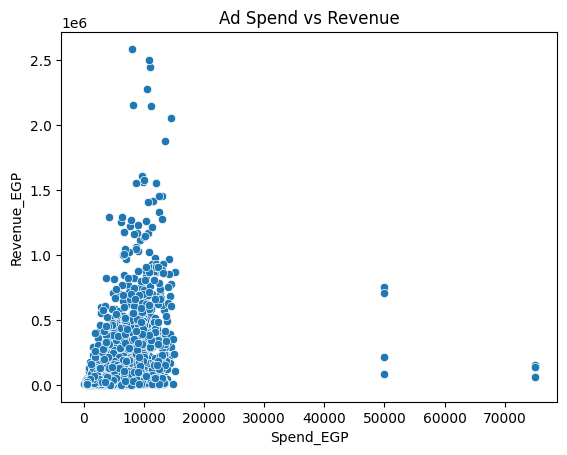

In [41]:
#Are higher spend levels associated with higher revenue or better ROAS?
sns.scatterplot(data=mkt_df, x="Spend_EGP", y="Revenue_EGP")
plt.title("Ad Spend vs Revenue")
plt.show()

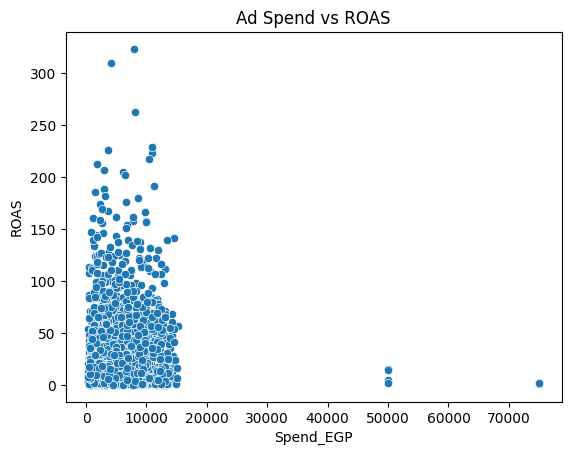

In [42]:
sns.scatterplot(data=mkt_df, x="Spend_EGP", y="ROAS")
plt.title("Ad Spend vs ROAS")
plt.show()

#Q : • How should the next campaign budget be allocated, and what would you test next?

> **Based on the charts Above, I cannot determine an exact budget for each campaign. I would prioritize campaigns that generated higher revenue with lower spend, while reserving part of the budget to test higher-spend campaigns and compare their results.**

In [43]:
# تأكد من أنواع البيانات
cols = ['CTR', 'CVR', 'CPC', 'CPA', 'ROAS']

mkt_df[cols] = mkt_df[cols].apply(pd.to_numeric, errors='coerce')

# Export CSV
mkt_df.to_csv('Marketing_Cleaned.csv', index=False, encoding='utf-8-sig')

In [44]:
'''mkt_df.to_csv("marketing_campaign_after_clean.csv", index=False)'''

from google.colab import files
files.download("Marketing_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>